# 02 — Limpeza

**Pergunta deste notebook:** que regras aplicar aos dados, e porquê cada uma.

O `01_eda` terminou com uma lista de problemas. Este notebook decide o que
fazer a cada um e produz `data/processed/anuncios_coimbra.csv`.

## Como este notebook funciona

Cada regra passa por três passos, sempre pela mesma ordem:

1. **Inspeccionar** — ver as linhas que a regra afectaria, com o título à vista
2. **Decidir** — escrever a decisão e a justificação
3. **Aplicar** — só no fim, tudo de uma vez, na secção 10

O `df` original **não é alterado ao longo do notebook**. É de propósito:
permite voltar atrás, comparar, e garante que a ordem por que se lê é a ordem
por que as regras se aplicam.

## Decisões do `01` que precisam de ser revistas

Três conclusões do notebook anterior eram demasiado grosseiras para se
aplicarem como estavam:

- **"remover os 118 marcados como tipo errado"** — a marcação nunca foi
  validada. Antes de apagar 7,6% dos dados é preciso ver o que lá está.
- **"cortar preço/m² pelos percentis"** — um corte por percentil remove sempre
  1% de cada lado, haja ou não problema. O limite tem de ser justificado pelo
  que os anúncios são.
- **"anos futuros = obra por concluir"** — a hipótese só se confirmou em
  metade dos casos.

## Setup

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

from src.config import INTERIM, PROCESSED, FREGUESIAS

df = pd.read_csv(INTERIM / "anuncios_completo.csv")
print(f"{len(df)} anúncios, {df.shape[1]} colunas")

1548 anúncios, 58 colunas


In [2]:
COLS_VER = ["titulo", "preco_eur", "area_m2", "preco_m2",
            "tipologia", "tipo_imovel", "bairro"]


def inspeccionar(df, condicao, cols=COLS_VER, n=15, nome=""):
    """
    Mostra as linhas que uma regra afectaria, sem as remover.

    O `titulo` vem sempre à frente: é lendo os títulos que se percebe se uma
    regra está a apanhar o que devia. Uma contagem sozinha não chega.
    """
    sub = df[condicao]
    print(f"{nome}: {len(sub)} anúncios ({100*len(sub)/len(df):.1f}% de {len(df)})")
    return sub[list(cols)].head(n)

---
## 0. Ponto de partida

Números de referência para o antes/depois no fim.

In [3]:
print(f"anúncios ............ {len(df)}")
print(f"colunas ............. {df.shape[1]}")
print(f"com preço e área .... {df[['preco_eur','area_m2']].notna().all(axis=1).sum()}")
print(f"com coordenadas ..... {df.lat.notna().sum()}")
print(f"apartamentos ........ {(df.tipo_imovel=='FLAT').sum()}")
print(f"moradias ............ {(df.tipo_imovel=='HOUSE').sum()}")
print(f"preço/m² mediano .... {df.preco_m2.median():.0f} €")

anúncios ............ 1548
colunas ............. 58
com preço e área .... 1532
com coordenadas ..... 1530
apartamentos ........ 1301
moradias ............ 246
preço/m² mediano .... 3961 €


---
## 1. Colunas sem informação

Três grupos, por razões diferentes. Nenhuma destas remoções envolve juízo —
são colunas que não podem informar nada.

In [4]:
CONSTANTES = ["distrito", "distrito_id", "concelho", "concelho_id",
              "transacao", "estado_anuncio"]
VAZIAS = ["erro"]

# Pares que dizem o mesmo: fica o primeiro, sai o segundo.
REDUNDANTES = {
    "divisoes_raw": "duplica tipologia",
    "piso_raw": "duplica piso",
    "bairro_id": "duplica bairro",
    "freguesia_id": "duplica freguesia",
    "preco_m2_site": "duplica preco_m2",
    "distancia_exacta": "duplica raio_precisao_m"
}

# Não descrevem o imóvel — descrevem a recolha ou identificam a linha.
METADADOS = {
    "pesquisa": "metadado da recolha (tipo x freguesia)",
    "agencia_id": "identificador, não é medida",
    "slug": "identificador",
    "url": "identificador",
}

for nome, cols in [("constantes", CONSTANTES), ("vazias", VAZIAS),
                   ("redundantes", list(REDUNDANTES)), ("metadados", list(METADADOS))]:
    print(f"{nome:14s} ({len(cols)}): {', '.join(cols)}")

A_REMOVER = CONSTANTES + VAZIAS + list(REDUNDANTES) + list(METADADOS)
print(f"total a remover: {len(A_REMOVER)} colunas -> restam {df.shape[1]-len(A_REMOVER)}")

constantes     (6): distrito, distrito_id, concelho, concelho_id, transacao, estado_anuncio
vazias         (1): erro
redundantes    (6): divisoes_raw, piso_raw, bairro_id, freguesia_id, preco_m2_site, distancia_exacta
metadados      (4): pesquisa, agencia_id, slug, url
total a remover: 17 colunas -> restam 41


**Duas por decidir:** o `raio_precisao_m` e o `distancia_exacta` não entram no
modelo (descrevem a qualidade da medição, não o imóvel), 
vou ficar com o `raio_precisao_m` e tirar o `distancia_exata`, porque são a mesma informação o `distancia_exacta` é literalmente `raio_precisao_m `== 0. Manter as duas é duplicação. E o `raio_precisao_m` é mais rico: tem três níveis (0, 100, 500) contra dois.

---
## 2. Datas e tempo em mercado

O `01` identificou que as datas estavam por converter.

A `data_publicacao` é a da primeira publicação; a `data_republicacao` é
actualizada pelo site e não serve para medir tempo em mercado.

convertidas .......... 1501 de 1548
sem data (sentinela) . 47
count    1501.0
mean      219.0
std       277.0
min         9.0
25%        63.0
50%       132.0
75%       257.0
max      3608.0


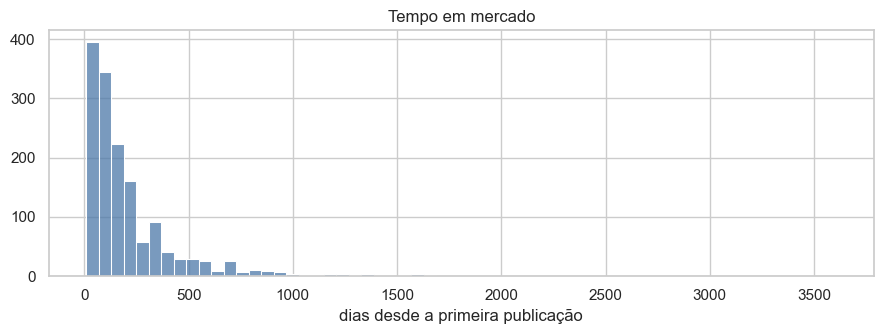

In [5]:
datas = pd.to_datetime(df["data_publicacao"], format="ISO8601",
                       utc=True, errors="coerce")
dias = (pd.Timestamp.now(tz="UTC") - datas).dt.days

print(f"convertidas .......... {datas.notna().sum()} de {len(df)}")
print(f"sem data (sentinela) . {datas.isna().sum()}")
print(dias.describe().round(0).to_string())

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(dias.dropna(), bins=60, color="#4C78A8", ax=ax)
ax.set_xlabel("dias desde a primeira publicação"); ax.set_ylabel("")
ax.set_title("Tempo em mercado")
plt.tight_layout(); plt.show()

**Os que não têm data** - Os 47 sem data ficam a nulo — não se inventa uma data de
publicação.

---
## 3. Validar a marcação `suspeito_tipo_errado`

A conclusão do `01` dizia "remover os 118". Antes disso: a regra apanha o que
devia, e só isso?

Duas perguntas separadas:

- **falsos positivos** — está a marcar apartamentos legítimos?
- **falsos negativos** — há prédios e terrenos que lhe escaparam?

A função marcar_suspeito. A coluna é True se qualquer uma de três condições se verificar.

Condição 1 — o título menciona algo que não é habitação

Condição 2 — T9+ com área grande, listado como apartamento

Condição 3 — o título diz "moradia" mas está listado como apartamento

In [6]:
inspeccionar(df, df.suspeito_tipo_errado, n=20, nome="MARCADOS")

MARCADOS: 118 anúncios (7.6% de 1548)


,titulo,preco_eur,area_m2,preco_m2,tipologia,tipo_imovel,bairro
4,"Investimento em Coimbra: Prédio com 8,7% Yield Projetada!",1050000.0,781.00,1344.43,T9+,FLAT,Celas
16,Prédio para Investimento | Olivais – Coimbra,575000.0,500.00,1150.00,T9+,FLAT,Bairro Norton de Matos
25,Prédio com Restaurante e com 2 apartamentos em Coimbra,600000.0,501.00,1197.60,T9+,FLAT,Olivais
183,Prédio T6 no Tovim,550000.0,136.00,4044.12,T9+,FLAT,Tovim - Casal do Lobo - Vale de Canas
502,️ Prédio no centro de Coimbra — junto ao Hospital da Universidade.,800000.0,670.00,1194.03,T9+,FLAT,Celas
552,"Apartamento T2 | Lote 29 | Quinta da Maia, Coimbra",330000.0,61.00,5409.84,T2,FLAT,Olivais
553,"Apartamento T2 | Lote 28 | Quinta da Maia, Coimbra",327500.0,61.00,5368.85,T2,FLAT,Olivais
555,"Apartamento T2 | Lote 27 | Quinta da Maia, Coimbra",345000.0,61.00,5655.74,T2,FLAT,Olivais
557,OPORTUNIDADE ÚNICA – DOIS PRÉDIOS COMERCIAIS E HABITACIONAIS EM C...,850000.0,536.00,1585.82,T9+,FLAT,Celas
580,Prédio para venda,1150000.0,351.00,3276.35,T9+,FLAT,Alta - Praça da República


Nem todos os anuncios marcados com suspeito_tipo-errado estao necessariamente mal classificados:

lote = lote dentro do empreendimento  |	Apartamento T2 | Lote 29 | Quinta da Maia

prédio = onde o imóvel está           |	Vende-se T2 Mobilado em prédio com elevador

loja dentro de um nome de sítio	      | T0 NOVO ... Junto à **Loja** Cidadão


In [7]:
tem_tipologia = df.titulo.str.contains(r"\bT\d", regex=True, na=False)

# A tipologia no título indica que se vende uma fracção — mas só se a coluna
# `tipologia` também não for T9+. Sem esta segunda condição, títulos como
# "Prédio p/recuperar T21" ou "Prédio c/ três apartamentos T4" seriam
# desmarcados por engano: têm um "T" com número, mas são prédios inteiros.
MANTER_APESAR_DA_MARCA = {
    18924455: "moradia com lote anexo — 'Terreno' aparece como acessório",
}
# A correcção desmarca anúncios com tipologia no título — mas quando o próprio
# título anuncia terreno ou logradouro à venda, o preço inclui área que não
# está no `area_m2`, e o €/m² não é comparável. Excepção à excepção.
PADRAO_VENDE_TERRENO = r"\bterreno\b|logradouro|com lote|lote de \d|\bquintal\b"
vende_terreno = df.titulo.str.contains(PADRAO_VENDE_TERRENO, case=False, na=False)

FALSO_POSITIVO = (df.suspeito_tipo_errado
                  & (tem_tipologia | df.ad_id.isin(MANTER_APESAR_DA_MARCA))
                  & (df.tipologia != "T9+")
                  & ~vende_terreno)

print(f"{FALSO_POSITIVO.sum()} de {df.suspeito_tipo_errado.sum()} marcações a corrigir "
      f"({100*FALSO_POSITIVO.sum()/df.suspeito_tipo_errado.sum():.0f}% de falsos positivos)")
df.loc[FALSO_POSITIVO, ["ad_id", "titulo", "tipologia", "area_m2"]]

10 de 118 marcações a corrigir (8% de falsos positivos)


,ad_id,titulo,tipologia,area_m2
552,18660674,"Apartamento T2 | Lote 29 | Quinta da Maia, Coimbra",T2,61.0
553,18660653,"Apartamento T2 | Lote 28 | Quinta da Maia, Coimbra",T2,61.0
555,18660648,"Apartamento T2 | Lote 27 | Quinta da Maia, Coimbra",T2,61.0
582,91866064800067,"Apartamento T2 | Lote 27 | Quinta da Maia, Coimbra",T2,61.0
623,19188867,Vende-se T2 Mobilado em prédio com elevador.,T2,90.0
715,19053151,T0 NOVO 41m2 | 3R | Mobiliado e Equipado | Junto à Loja Cidadão | ...,T0,37.0
716,19052972,T0 NOVO 41m2 | 3R | Mobiliado e Equipado | Junto à Loja Cidadão | ...,T0,41.0
1193,18937718,NOVO - Prédio T1´s e T2´s na Guarda Inglesa,T2,88.0
1303,19252547,Moradia T3 em rúina inserida num lote com 336m2 à venda em Coimbra,T3,68.0
1356,18911768,Moradia T4 | Lote 1 | Quinta da Portela,T4,219.0


In [8]:
# Não marcados, mas com preço/m² fora do razoável -> candidatos a falso negativo
suspeitos_por_valor = (~df.suspeito_tipo_errado) & (
    (df.preco_m2 > 8000) | (df.preco_m2 < 800))

inspeccionar(df, suspeitos_por_valor, n=30, nome="NÃO MARCADOS, valor extremo")

NÃO MARCADOS, valor extremo: 30 anúncios (1.9% de 1548)


,titulo,preco_eur,area_m2,preco_m2,tipologia,tipo_imovel,bairro
38,Apartamento T2 para arrendar,800.0,70.00,11.43,T2,FLAT,Bairro Norton de Matos
269,NOVA CONSTRUÇÂO - T4 com piscina - Quinta da Portela,1300000.0,154.28,8426.24,T4,FLAT,Alto de S. João - Portela - Pinhal de Marrocos
416,NOVA CONSTRUÇÂO - T4 com piscina - Quinta da Portela,1300000.0,154.00,8441.56,T4,FLAT,Alto de S. João - Portela - Pinhal de Marrocos
421,"Apartamento T2, Avenidas Novas - Lisboa",1340000.0,132.00,10151.52,T2,FLAT,Bairro Norton de Matos
926,Apartamento T0 para venda,214800.0,25.20,8523.81,T0,FLAT,Santa Clara
1323,"Moradia T4 | Rua da Mãozinha, Coimbra",1250000.0,107.50,11627.91,T4,HOUSE,Olivais
1336,"Quinta do Engenho, Penela",300000.0,1218.00,246.31,NaN,HOUSE,Bairro Norton de Matos
1345,"Quinta do Engenho, Penela",300000.0,1218.00,246.31,NaN,HOUSE,Bairro Norton de Matos
1348,Casa emCastedo-Torre de Moncorvo,40000.0,115.00,347.83,T5,HOUSE,Quinta da Maia
1354,Moradia T2 para venda,280000.0,33.00,8484.85,T2,HOUSE,Alto de S. João - Portela - Pinhal de Marrocos



O suspeito_tipo_errado parece falhar a identificar casas moveis , e tambem é possivel verificar que existem sitios fora de coimbra que estao no dataset. (Penela, Moncorvo...)

In [9]:
# Casos confirmados um a um na tabela acima. Removidos pelo ad_id porque são
# irregulares demais para uma regra — e uma regra feita à medida destes
# apanharia anúncios legítimos.
REMOVER_MANUALMENTE = {
    19096148: "quinta/herdade de 23 000 m² — terreno, não habitação",
    19180969: "casas móveis",
    19201316: "casa móvel de 6 metros",
    19141246: "restaurante com AL — imóvel comercial; os 3 756 m² não são habitação",
    19207052: "1,25 M€ incluem terreno de 969 m² que não está na área — €/m² não comparável",
    18995678: "área declarada 33 m², mas o incluem terreno de 969 m² e 4 quartos — dados errados",
    19085114: "venda conjunta de 2 moradias, uma delas ocupada — não é uma habitação"
}


print(f"{len(REMOVER_MANUALMENTE)} anúncios a remover à mão")
df[df.ad_id.isin(REMOVER_MANUALMENTE)][["ad_id", "titulo", "preco_eur", "area_m2"]]

7 anúncios a remover à mão


,ad_id,titulo,preco_eur,area_m2
1323,19207052,"Moradia T4 | Rua da Mãozinha, Coimbra",1250000.0,107.5
1354,18995678,Moradia T2 para venda,280000.0,33.0
1393,19141246,Propriedade Habitacional | Restaurante | AL com 9 Suites Premium.,1249900.0,3756.0
1397,19085114,Moradia T4 para venda,157500.0,243.0
1420,19201316,Mobile home 6 metros,13000.0,18.0
1422,19180969,"Venda de duas casas móveis, mobile homes",11000.0,30.0
1472,19096148,Venda Quinta/Herdade,675000.0,23000.0


In [10]:
# Depois de corrigir e de remover os casos manuais, o que resta nos extremos?
resta = (~df.suspeito_tipo_errado | FALSO_POSITIVO) & \
        ~df.ad_id.isin(REMOVER_MANUALMENTE) & \
        ~df.suspeito_arrendamento & \
        ((df.preco_m2 > 8000) | (df.preco_m2 < 800))

print("Extremos que sobram — são imóveis reais?")
df[resta][["ad_id", "titulo", "preco_eur", "area_m2", "preco_m2"]].sort_values("preco_m2")

Extremos que sobram — são imóveis reais?


,ad_id,titulo,preco_eur,area_m2,preco_m2
1485,18963465,Moradia Castelo Viegas,25000.0,120.00,208.33
1345,18602225,"Quinta do Engenho, Penela",300000.0,1218.00,246.31
1336,19169143,"Quinta do Engenho, Penela",300000.0,1218.00,246.31
1465,19149548,Venda Moradia,25000.0,80.00,312.50
1348,19057765,Casa emCastedo-Torre de Moncorvo,40000.0,115.00,347.83
1409,18126480,Moradia T3 para venda,75000.0,189.15,396.51
1361,18809347,vendo casa com adega em coleja,50000.0,120.00,416.67
1492,18579246,"Moradia para Reconstrução em Cruz dos Morouços, Santa Clara",80000.0,168.00,476.19
1424,19169126,"Moradia T3 para recuperar na Pedrulha, Coimbra",90000.0,175.00,514.29
1436,16932052,Casa para Reconstrução (Coimbra),52500.0,100.00,525.00


O dataset continua a esta danificado por imóveis de zonas fora da zona de estudo (Penela, Moncorvo, Lisboa...)

---
## 4. Anúncios fora do âmbito

Ao inspeccionar a secção 3.

A localização estruturada (`freguesia`, `bairro`, `lat`/`lon`) vem do site e
segue o que a agência introduziu. Quando a agência erra, a localização erra com
ela, e as coordenadas ficam dentro de Coimbra na mesma.

Ou seja: **não há forma geométrica de apanhar estes casos.** Só o título.

In [11]:
FORA_DO_AMBITO = r"lisboa|porto|penela|moncorvo|figueira|aveiro|leiria|viseu|coleja|cernache"

inspeccionar(df, df.titulo.str.contains(FORA_DO_AMBITO, case=False, na=False),
             cols=["titulo", "freguesia", "bairro", "preco_m2"],
             n=15, nome="Título menciona outro concelho")

Título menciona outro concelho: 13 anúncios (0.8% de 1548)


,titulo,freguesia,bairro,preco_m2
398,"Apartamento T1, Travessa Alferes Malheiro - Porto",Santo António dos Olivais,Bairro Norton de Matos,5970.15
399,"Apartamento T2, Travessa Alferes Malheiro - Porto",Santo António dos Olivais,Bairro Norton de Matos,6480.52
400,"Apartamento, T1, Travessa de Alferes Malheiro - Porto",Santo António dos Olivais,Bairro Norton de Matos,7046.51
420,"Apartamento T2, Travessa Alferes Malheiro - Porto",Santo António dos Olivais,Bairro Norton de Matos,6189.87
421,"Apartamento T2, Avenidas Novas - Lisboa",Santo António dos Olivais,Bairro Norton de Matos,10151.52
730,"Apartamento para Reabilitação na Rua Figueira da Foz, Coimbra","Sé Nova, Santa Cruz, Almedina e São Bartolomeu",Baixa,2042.55
733,"Prédio para Reabilitação, Rua Figueira da Foz, Coimbra","Sé Nova, Santa Cruz, Almedina e São Bartolomeu",Baixa,1989.47
810,Apartamento para venda na rua de aveiro - 3 Quartos e 3 WC,"Sé Nova, Santa Cruz, Almedina e São Bartolomeu",Baixa,2938.14
1313,Moradia Tradicional Remodelada T4 em Cernache,Santo António dos Olivais,Celas,989.58
1336,"Quinta do Engenho, Penela",Santo António dos Olivais,Bairro Norton de Matos,246.31


In [12]:
# Controlo: os pontos estão todos dentro da caixa geográfica de Coimbra?
d = df.dropna(subset=["lat", "lon"])
fora_caixa = (d.lat < 40.13) | (d.lat > 40.29) | (d.lon < -8.52) | (d.lon > -8.36)
print(f"pontos fora da caixa de Coimbra: {fora_caixa.sum()}")

slugs = {f"coimbra/coimbra/{s}" for s in FREGUESIAS.values()}
print(f"anúncios fora das 5 freguesias: {(~df.freguesia_id.isin(slugs)).sum()}")
print(df[~df.freguesia_id.isin(slugs)].freguesia.value_counts().to_string())

pontos fora da caixa de Coimbra: 0
anúncios fora das 5 freguesias: 3
freguesia
Torres do Mondego    3


Fiz assim um double check, elimino pelos titulos que vi de outras zonas e verifico pelos anuncios que estao fora da caixa de Coimbra

---
## 5. Preço

Dois problemas distintos: anúncios sem preço, e anúncios com preço extremo.

In [13]:
inspeccionar(df, df.preco_eur.isna(),
             cols=["titulo", "preco_oculto", "area_m2", "tipo_imovel"],
             n=20, nome="SEM PREÇO")

SEM PREÇO: 16 anúncios (1.0% de 1548)


,titulo,preco_oculto,area_m2,tipo_imovel
45,Apartamento T2 com Sótão na Solum,True,74.00,FLAT
173,Grande T5 Duplex + terraço + garagem,True,250.00,FLAT
197,Apartamento T2 Rua de Macau Bairro Norton de Matos - Remodelado,True,60.00,FLAT
274,T4 em último piso no condomínio fechado ZEN,True,185.00,FLAT
382,T4 em último piso no condomínio fechado ZEN,True,185.00,FLAT
516,Apartamento T4 | Condomínio Zen | Quinta da Portela,True,200.00,FLAT
518,Apartamento T4 | Condomínio Zen | Quinta da Portela,True,200.00,FLAT
551,Apartamento T4 para venda,True,174.00,FLAT
554,Apartamento T4 | Condomínio Zen | Quinta da Portela,True,200.00,FLAT
578,Apartamento T3 com varanda e garagem para 2 carros,True,125.00,FLAT


Não irei remover os valores sem preço, não servem para treinar o modelo,
mas são exactamente os casos em que o querer usar faz sentido — imóveis a
que se quer atribuir um valor estimado. Ficam de parte, para o 03.

In [14]:
# Simula todas as regras de categoria para ver o que sobra nos extremos.
# É esta simulação que decide os limites por valor — não os percentis.
ja_sai = ((df.suspeito_tipo_errado & ~FALSO_POSITIVO)
          | df.suspeito_arrendamento
          | df.ad_id.isin(REMOVER_MANUALMENTE)
          | df.titulo.str.contains(FORA_DO_AMBITO, case=False, na=False))

resta = df[~ja_sai].dropna(subset=["preco_m2"])

print(f"saem por regras de categoria .... {ja_sai.sum()} ({100*ja_sai.mean():.1f}%)")
print(f"restam com preço ............... {len(resta)}")
print(f"preço/m² mínimo que sobra ...... {resta.preco_m2.min():.0f}")
print(f"preço/m² máximo que sobra ...... {resta.preco_m2.max():.0f}")
print("=== 12 mais baratos que sobram ===")
display(resta.sort_values("preco_m2", ascending=True).head(12)[
    ["ad_id", "titulo", "preco_eur", "area_m2", "preco_m2", "estado_conservacao"]])

print("=== 12 mais caros que sobram ===")
display(resta.sort_values("preco_m2", ascending=False).head(12)[
    ["ad_id", "titulo", "preco_eur", "area_m2", "preco_m2", "tipologia"]])

saem por regras de categoria .... 128 (8.3%)
restam com preço ............... 1406
preço/m² mínimo que sobra ...... 208
preço/m² máximo que sobra ...... 8524
=== 12 mais baratos que sobram ===


,ad_id,titulo,preco_eur,area_m2,preco_m2,estado_conservacao
1485,18963465,Moradia Castelo Viegas,25000.0,120.00,208.33,to_renovation
1465,19149548,Venda Moradia,25000.0,80.00,312.50,to_renovation
1409,18126480,Moradia T3 para venda,75000.0,189.15,396.51,NaN
1492,18579246,"Moradia para Reconstrução em Cruz dos Morouços, Santa Clara",80000.0,168.00,476.19,to_renovation
1424,19169126,"Moradia T3 para recuperar na Pedrulha, Coimbra",90000.0,175.00,514.29,to_renovation
1436,16932052,Casa para Reconstrução (Coimbra),52500.0,100.00,525.00,to_renovation
1546,17459024,Casa para recuperar - São Martinho do Bispo - Coimbra,57500.0,100.00,575.00,to_renovation
1396,19116105,Casa / Villa T2 em Torres do Mondego de 64 m2,39000.0,64.00,609.38,to_renovation
1539,18875820,Moradia com projecto de reconstrução aprovado pela CMC,95000.0,144.00,659.72,NaN
1473,19073883,Moradia P/Recuperar em Ceira,60000.0,90.00,666.67,to_renovation


=== 12 mais caros que sobram ===


,ad_id,titulo,preco_eur,area_m2,preco_m2,tipologia
926,19245663,Apartamento T0 para venda,214800.0,25.20,8523.81,T0
416,19068187,NOVA CONSTRUÇÂO - T4 com piscina - Quinta da Portela,1300000.0,154.00,8441.56,T4
269,19151885,NOVA CONSTRUÇÂO - T4 com piscina - Quinta da Portela,1300000.0,154.28,8426.24,T4
427,19065814,Apartamento T4 - Quinta da Portela - Coimbra/Venda,1300000.0,164.07,7923.45,T4
489,19005758,Apartamento T1 - Olivais,310000.0,40.00,7750.00,T1
530,18874358,Estúdio com aparcamento em zona da Quinta da Portela,215000.0,28.00,7678.57,T0
24,19091253,Apartamento T4 com piscina - Quinta da Portela,1150000.0,150.00,7666.67,T4
556,18647752,Apartamento T2 para venda,340000.0,45.00,7555.56,T2
531,18874233,Estúdio em zona da Quinta da Portela,210000.0,28.00,7500.00,T0
347,19116714,APARTAMENTO T0 | CELAS | NOVO,216000.0,29.00,7448.28,T1


In [15]:
LIMITE_INF = 200   # nada a cortar — o mais barato legítimo tem 208 €/m²
LIMITE_SUP = 15000   # nada a cortar — os caros são obra nova real

**Extremos**
As regras de categoria já fizeram quase tudo: saem 113 anúncios (7,3%) e
sobram 1 421 com preço, entre 208 e 11 628 €/m².

Os mais baratos são todos legítimos. São moradias para recuperar, e a
maioria está marcada to_renovation. A mais barata — Moradia Castelo
Viegas, 25 000 € por 120 m² — é uma casa a sério em ruína. Um preço/m² de
208 € não é erro, é o preço de uma casa que precisa de obras.

Os mais caros também. Obra nova na Quinta da Portela a 8 400 €/m² e
estúdios em Celas a 7 500 €/m². Coimbra tem mesmo estes preços.

Ou seja: não há contaminação nos extremos. Se tivesse cortado pelos
percentis p01/p99, como pensava no 01, teria apagado 10 ruínas legítimas
e vários estúdios reais.

**Limites**
LIMITE_INF = 200 e LIMITE_SUP = 15000 não removem nenhuma linha hoje.
São rede de segurança para recolhas futuras, não correcção de um problema
atual.

Duas linhas com área que não corresponde ao imóvel. Fui verificar os
anúncios:

Moradia T4, Rua da Mãozinha — 1,25 M€ por 107,5 m², mas está inserida
num terreno de 430 m². O preço inclui terreno que não está na área, tal
como acontecia na quinta.
Moradia T2 para venda — 33 m² declarados, mas a descrição indica 969 m²
de área de terreno. A área está errada e
a tipologia também.

Ambas removidas à mão. A segunda podia ser corrigida — tenho a informação —
mas corrigir um caso isolado a partir da descrição, sem o fazer para os
restantes 1 548, seria arbitrário. Extrair áreas das descrições de forma
sistemática fica como melhoria futura.

---
## 6. Área

In [16]:

print("=== 10 maiores áreas ===")
display(resta.sort_values("area_m2", ascending=False).head(12)[
    ["ad_id", "titulo", "preco_eur", "area_m2", "preco_m2", "tipologia"]])

print("=== 10 menores áreas ===")
display(resta.sort_values("area_m2", ascending=True).head(12)[
    ["ad_id", "titulo", "preco_eur", "area_m2", "preco_m2", "tipologia"]])

=== 10 maiores áreas ===


,ad_id,titulo,preco_eur,area_m2,preco_m2,tipologia
1364,16253512,Moradia exclusiva em zona nobre de Coimbra,2490000.0,870.00,2862.07,T9+
1451,19185431,Moradia T5+2 - Carvalhais - Coimbra/Venda,755000.0,551.00,1370.24,T7
1378,17199339,Moradia T9 para venda,700000.0,508.00,1377.95,T9
1370,17200846,Moradia localizada em zona residencial junto à Avenida Dias da Silva,700000.0,508.00,1377.95,T7
1346,19063392,Moradia T6 para venda,980000.0,436.97,2242.72,T6
1433,18724950,Moradia T9 para venda,1250000.0,406.00,3078.82,T9
1481,18886532,Moradia muito bem localizada,700000.0,400.00,1750.00,T4
1453,19208364,Moradia T6+3 c/ Piscina e Garagem - Coimbra,538000.0,400.00,1345.00,T9
1458,19197052,Moradia T5 na Quinta do Limoeiro Antanhol,598000.0,398.00,1502.51,T5
1325,18924467,moradia independente na Cruz de Celas - exclusivo Rmcasa,750000.0,387.00,1937.98,T6


=== 10 menores áreas ===


,ad_id,titulo,preco_eur,area_m2,preco_m2,tipologia
881,18712075,Apartamento T0 para venda,155000.0,21.30,7277.00,T0
926,19245663,Apartamento T0 para venda,214800.0,25.20,8523.81,T0
790,19153134,Estúdio T0 para venda,165000.0,27.00,6111.11,T0
531,18874233,Estúdio em zona da Quinta da Portela,210000.0,28.00,7500.00,T0
530,18874358,Estúdio com aparcamento em zona da Quinta da Portela,215000.0,28.00,7678.57,T0
235,19166549,T0 Premium em zona privilegiada de Coimbra,200000.0,29.00,6896.55,T0
84,19225708,"Apartamento T0 com aparcamento, Maozinha em Coimbra",215500.0,29.00,7431.03,T0
347,19116714,APARTAMENTO T0 | CELAS | NOVO,216000.0,29.00,7448.28,T1
346,19116715,APARTAMENTO T0 | CELAS | NOVO,190000.0,29.00,6551.72,T0
350,19111352,APARTAMENTO T0 | CELAS | NOVO,199000.0,29.00,6862.07,T1


As 12 maiores são moradias de luxo reais: 870 m² em zona nobre, T5 e T7 em Carvalhais e na Dias da Silva. Áreas grandes porque são casas grandes.

As 12 menores são todas T0 e estúdios, entre 21 e 31 m², em Celas e na Quinta da Portela. Um estúdio de 21 m² é pequeno mas existe.

---
## 7. `ano_construcao`

Três problemas: um valor impossível, 302 anos no futuro, e 38% em falta de
forma não-aleatória.

A hipótese do `01` — anos futuros = obra por concluir — só se confirmou em
metade dos casos.

In [17]:
inspeccionar(df, df.ano_construcao < 1900,
             cols=["titulo", "ano_construcao", "estado_conservacao", "preco_m2","preco_eur"],
             n=10, nome="ano < 1900")

ano < 1900: 2 anúncios (0.1% de 1548)


,titulo,ano_construcao,estado_conservacao,preco_m2,preco_eur
132,Apartamento T3 para venda,189.0,NaN,3650.79,345000.0
1434,Quinta T4 para venda,1892.0,NaN,4330.71,550000.0


In [18]:
fut = df[df.ano_construcao > 2026]
print(f"anos futuros: {len(fut)}")
print(fut.estado_conservacao.value_counts(dropna=False).to_string())

display(fut[fut.estado_conservacao != "to_completion"]
        [["titulo", "ano_construcao", "estado_conservacao", "mercado", "preco_m2"]].head(15))

anos futuros: 303
estado_conservacao
to_completion    139
ready_to_use      83
NaN               81


,titulo,ano_construcao,estado_conservacao,mercado,preco_m2
24,Apartamento T4 com piscina - Quinta da Portela,2027.0,ready_to_use,primary,7666.67
67,Apartamento T1 para venda,2029.0,ready_to_use,primary,5377.21
84,"Apartamento T0 com aparcamento, Maozinha em Coimbra",2029.0,ready_to_use,primary,7431.03
176,Apartamento T2 com garagem e terraço em zona da Solum,2027.0,ready_to_use,primary,5901.64
177,"Apartamento T2 com garagem em zona da Solum, Coimbra",2027.0,ready_to_use,primary,5725.81
178,Apartamento T3 com garagem e terraço em zona da Solum,2027.0,ready_to_use,primary,5059.52
251,Apartamento T1 para venda,2029.0,ready_to_use,primary,5459.25
252,Apartamento T1 para venda,2029.0,ready_to_use,primary,5317.01
254,NOVA CONSTRUÇÂO - T4 com piscina - Quinta da Portela,2028.0,ready_to_use,secondary,7411.70
256,NOVA CONSTRUÇÂO - T4 - Quinta da Portela,2028.0,ready_to_use,secondary,4514.51


Dois anos anteriores a 1900. O 189 é gralha — pode ser 1890, 1980 ou
1989, e não há forma de saber. 
Posto a nulo. O 1892 é plausível: uma quinta
no século XIX, com preço/m² normal. Fica.

303 anos no futuro (2027–2029), e não são erro. A hipótese do 01 era
que correspondiam a obra por concluir. Cruzando com estado_conservacao e
mercado, vê-se que a explicação é outra: os promotores usam o campo como
"ano previsto de conclusão", mas preenchem os restantes de forma
inconsistente — 156 estão marcados como secondary (usado) e 83 como
ready_to_use, ambos contraditórios com um ano futuro.

Não se calcula idade para estes: uma idade negativa não significa nada.
Criei obra_nova e deixei idade_edificio a nulo.

---
## 8. Colunas multi-valor

Expandir `extras`, `tags` e `seguranca` em binárias, e escolher entre `tags` e
`extras`, que duplicam a informação.

In [19]:
def expandir_multivalor(df, coluna, sep="|", min_n=20):
    """Uma coluna binária por valor presente em pelo menos `min_n` anúncios."""
    s = df[coluna].dropna().astype(str)
    valores = sorted({v for linha in s for v in linha.split(sep)})
    listas = df[coluna].fillna("").astype(str).str.split(sep)
    out = pd.DataFrame(index=df.index)
    for v in valores:
        col = listas.apply(lambda xs: v in xs)
        if col.sum() >= min_n:
            out[f"{coluna}__{v}"] = col
    return out


ext = expandir_multivalor(df, "extras")
tgs = expandir_multivalor(df, "tags")
seg = expandir_multivalor(df, "seguranca")
print(f"extras -> {ext.shape[1]} | tags -> {tgs.shape[1]} | seguranca -> {seg.shape[1]}")

extras -> 10 | tags -> 11 | seguranca -> 4


In [20]:
# Quanto é que tags e extras coincidem, par a par?
PARES = [("tags__BALCONY", "extras__balcony"),
         ("tags__PARKING_SPOT", "extras__garage"),
         ("tags__AIR_CONDITIONING", "extras__air_conditioning"),
         ("tags__GARDEN", "extras__garden"),
         ("tags__TERRACE", "extras__terrace")]

juntas = pd.concat([tgs, ext], axis=1)
linhas = []
for a, b in PARES:
    if a in juntas and b in juntas:
        linhas.append({"tags": a, "extras": b,
                       "n_tags": int(juntas[a].sum()), "n_extras": int(juntas[b].sum()),
                       "concordancia_%": round(100*(juntas[a] == juntas[b]).mean(), 1)})
display(pd.DataFrame(linhas))

,tags,extras,n_tags,n_extras,concordancia_%
0,tags__BALCONY,extras__balcony,414,407,99.5
1,tags__PARKING_SPOT,extras__garage,665,679,98.1
2,tags__AIR_CONDITIONING,extras__air_conditioning,421,438,98.4
3,tags__GARDEN,extras__garden,78,78,100.0
4,tags__TERRACE,extras__terrace,120,120,100.0


In [21]:
# tags e extras são a mesma informação vinda de dois sítios: `tags` do JSON da
# listagem, `extras` do JSON da página de detalhe. Verificação: quando as duas
# estão preenchidas concordam em tudo menos 2 casos, em 1548 anúncios. Logo as
# diferenças são falta de informação, não contradição — e a união é segura.
#
# Os vocabulários não coincidem: além das maiúsculas, há sinónimos com nomes
# diferentes (PARKING_SPOT/garage, TWO_LEVEL/two_storey, STORAGE_ROOM/usable_room)
# e valores exclusivos de cada lado. Daí o mapa explícito.
CARACTERISTICAS = {
    # nome final          (tags,              extras)
    "ar_condicionado":   ("AIR_CONDITIONING", "air_conditioning"),
    "varanda":           ("BALCONY",          "balcony"),
    "cave":              ("BASEMENT",         "basement"),
    "jardim":            ("GARDEN",           "garden"),
    "piscina":           ("POOL",             "pool"),
    "cozinha_separada":  ("SEPARATE_KITCHEN", "separate_kitchen"),
    "terraco":           ("TERRACE",          "terrace"),
    "garagem":           ("PARKING_SPOT",     "garage"),
    "duplex":            ("TWO_LEVEL",        "two_storey"),
    "arrecadacao":       ("STORAGE_ROOM",     "usable_room"),
    # só existem numa das fontes
    "res_do_chao":       ("GROUND_FLOOR",     None),
    "edificio_seguro":   ("SECURE_BUILDING",  None),
    "ultimo_piso":       ("TOP_FLOOR",        None),
    "elevador":          (None,               "lift"),
    "sotao":             (None,               "attic"),
    "acessibilidade":    (None, "accessibility_for_people_with_reduced_mobility"),
}


def unir_caracteristicas(df, mapa=CARACTERISTICAS, min_n=20):
    """União de `tags` e `extras` numa só coluna binária por característica."""
    def tem(coluna, valor):
        if valor is None:
            return pd.Series(False, index=df.index)
        return (df[coluna].fillna("").astype(str)
                  .str.split("|").apply(lambda xs: valor in xs))

    out = pd.DataFrame(index=df.index)
    for nome, (t, e) in mapa.items():
        col = tem("tags", t) | tem("extras", e)
        if col.sum() >= min_n:
            out["tem_" + nome] = col
    return out


binarias = unir_caracteristicas(df)
print(f"{binarias.shape[1]} colunas binárias")
print(f"anúncios com pelo menos uma: {binarias.any(axis=1).sum()} "
      f"(só tags: {df.tags.notna().sum()} | só extras: {df.extras.notna().sum()})")
display(binarias.sum().sort_values(ascending=False).to_frame("n"))

13 colunas binárias
anúncios com pelo menos uma: 1086 (só tags: 1014 | só extras: 1040)


,n
tem_elevador,707
tem_garagem,687
tem_ar_condicionado,442
tem_varanda,414
tem_ultimo_piso,215
tem_acessibilidade,183
tem_edificio_seguro,152
tem_res_do_chao,147
tem_terraco,120
tem_jardim,78


In [22]:
#seguranca
def diagnostico_multivalor(df, coluna, target="preco_m2", sep="|", min_n=10):
    """Frequência de cada valor e efeito no alvo, para uma coluna multi-valor."""
    y = pd.to_numeric(df[target], errors="coerce")
    listas = df[coluna].fillna("").astype(str).str.split(sep)
    valores = sorted({v for xs in listas for v in xs if v})
    linhas = []
    for v in valores:
        tem = listas.apply(lambda xs: v in xs)
        com, sem = y[tem & y.notna()], y[~tem & y.notna()]
        if len(com) < min_n:
            continue
        linhas.append({"valor": v, "n": int(tem.sum()),
                       "pct": round(100 * tem.mean(), 1),
                       "mediana_com": round(com.median()),
                       "mediana_sem": round(sem.median()),
                       "diferenca": round(com.median() - sem.median())})
    return (pd.DataFrame(linhas)
            .sort_values("n", ascending=False).reset_index(drop=True))


display(diagnostico_multivalor(df, "seguranca"))

,valor,n,pct,mediana_com,mediana_sem,diferenca
0,entryphone,174,11.2,4487,3882,604
1,anti_burglary_door,97,6.3,4262,3909,353
2,roller_shutters,55,3.6,4612,3938,675
3,monitoring,20,1.3,3845,3964,-119
4,alarm,16,1.0,3522,3964,-442
5,closed_area,15,1.0,3935,3963,-28


preenchido: 214 (15%)  |  vazio: 1202
  preço/m² mediano ... com: 4495   sem: 3943
  ano construção ..... com: 2026   sem: 2025
  nº de fotos ........ com: 16.1   sem: 18.7


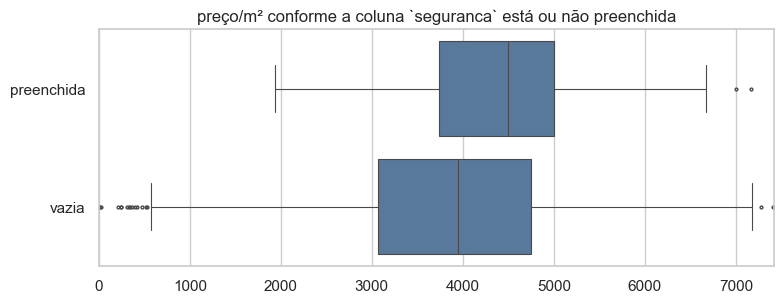

In [23]:
lim = df[~df.suspeito_tipo_errado].dropna(subset=["preco_m2"])
tem = lim.seguranca.notna()

print(f"preenchido: {tem.sum()} ({100*tem.mean():.0f}%)  |  vazio: {(~tem).sum()}")
print(f"  preço/m² mediano ... com: {lim[tem].preco_m2.median():.0f}   "
      f"sem: {lim[~tem].preco_m2.median():.0f}")
print(f"  ano construção ..... com: {lim[tem].ano_construcao.median():.0f}   "
      f"sem: {lim[~tem].ano_construcao.median():.0f}")
print(f"  nº de fotos ........ com: {lim[tem].n_fotos.mean():.1f}   "
      f"sem: {lim[~tem].n_fotos.mean():.1f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.boxplot(data=lim.assign(preenchida=tem.map({True: "preenchida", False: "vazia"})),
            x="preco_m2", y="preenchida", ax=ax, color="#4C78A8",
            fliersize=2, linewidth=.8)
ax.set_xlim(0, lim.preco_m2.quantile(.99))
ax.set_title("preço/m² conforme a coluna `seguranca` está ou não preenchida")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [24]:
# O `SECURE_BUILDING` das tags já cobre parte disto?
sb = df.tags.fillna("").str.contains("SECURE_BUILDING")
display(pd.crosstab(sb.rename("tags: SECURE_BUILDING"),
                    df.seguranca.notna().rename("seguranca preenchida")))

seguranca preenchida,False,True
tags: SECURE_BUILDING,,
False,1323,73
True,2,150


Quando tags e extras estão ambas preenchidas, concordam em tudo menos
2 casos em 1 548 anúncios. As diferenças são falta de informação — 457
anúncios não têm nenhuma das duas, 77 só têm extras, 51 só têm tags.
Escolher uma perderia esses.


---
## 9. Categorias raras

`agencia` tem 139 níveis e alguns bairros têm muito poucos anúncios.
Categorias com 3 ou 4 observações não sustentam nenhuma estimativa.

In [25]:
def categorias_raras(df, coluna, min_n=15):
    vc = df[coluna].value_counts()
    raras = vc[vc < min_n]
    print(f"{coluna}: {len(vc)} categorias, {len(raras)} com menos de {min_n} "
          f"anúncios (cobrem {raras.sum()} linhas, {100*raras.sum()/len(df):.1f}%)")
    return raras


display(categorias_raras(df, "bairro").to_frame("n"))
categorias_raras(df, "agencia", min_n=10)

bairro: 23 categorias, 5 com menos de 15 anúncios (cobrem 48 linhas, 3.1%)


,n
bairro,
Terraços do Rio,14
Maínça - Rocha Nova - Lordemão,13
Ribeira de Frades,10
Quinta dos Jerónimos,7
Chão do Bispo,4


agencia: 139 categorias, 111 com menos de 10 anúncios (cobrem 236 linhas, 15.2%)


agencia
N Prestige                                        9
Century21 Plano                                   9
FILOMENO PEREIRA                                  7
Seven Hills - Business Advisory Services, Lda.    7
REMAX PRO                                         7
                                                 ..
RH Real Estate By Renthouse                       1
Bulldog Projects - Arquitetura & Imobiliária      1
ImoCoimbra – Mediação Imobiliária                 1
CENTURY21 MOVE.ON                                 1
Micar                                             1
Name: count, Length: 111, dtype: int64

In [26]:
def agrupar_bairro(df, min_n=15):
    """
    Bairros com poucos anúncios sobem para o nome da freguesia. Preserva o
    significado geográfico, ao contrário de um balde "outros" que juntaria
    bairros distantes entre si.
    """
    vc = df.bairro.value_counts()
    raros = set(vc[vc < min_n].index)
    return df.bairro.where(~df.bairro.isin(raros),
                           df.freguesia + " (resto)")

In [27]:
# As redes imobiliárias têm vários escritórios em Coimbra: 12 nomes da RE/MAX,
# 8 da Century 21, 4 da ERA. Agrupar por marca é um critério com significado
# — cada rede tem posicionamento e política de preço próprios — ao contrário
# de um limiar de contagem, que é arbitrário.
MARCAS = {
    "RE/MAX":          r"re\s*/?\s*max",
    "ERA":             r"\bera\b",
    "Century 21":      r"century\s*-?\s*21",
    "Keller Williams": r"\bkw\b|keller\s*williams",
    "Zome":            r"\bzome\b",
    "Iad":             r"\biad\b",
    "Predimed":        r"predimed",
    "Safti":           r"\bsafti\b",
}


def agrupar_agencia(df, marcas=MARCAS, min_n=25):
    """
    Agrupa por marca; independentes com volume mantêm o nome; o resto colapsa.

    A ordem importa: primeiro as marcas, depois os particulares, e só no fim o
    critério de volume. Assim uma agência pequena de uma rede grande fica com a
    rede, e não no balde das independentes.
    """
    nomes = df["agencia"].fillna("").astype(str)
    grupo = pd.Series(pd.NA, index=df.index, dtype="object")

    for marca, padrao in marcas.items():
        m = grupo.isna() & nomes.str.contains(padrao, case=False, regex=True)
        grupo[m] = marca

    grupo[grupo.isna() & df["particular"].fillna(False)] = "Particular"

    resto = nomes[grupo.isna()]
    vc = resto.value_counts()
    grandes = set(vc[vc >= min_n].index)
    manter = grupo.isna() & nomes.isin(grandes)
    grupo[manter] = nomes[manter]

    grupo[grupo.isna() & (nomes != "")] = "Outra independente"
    grupo[grupo.isna()] = "(sem agência)"
    return grupo


df["agencia_grupo"] = agrupar_agencia(df)

print(f"{df.agencia.nunique()} agências -> {df.agencia_grupo.nunique()} grupos")
display(df.groupby("agencia_grupo")
          .agg(n=("preco_m2", "size"), preco_m2_mediano=("preco_m2", "median"))
          .sort_values("n", ascending=False).round(0))

139 agências -> 18 grupos


,n,preco_m2_mediano
agencia_grupo,,
RE/MAX,385,3699.0
Outra independente,344,3894.0
ERA,139,3969.0
Soluções Ideais - Imobiliária,115,4625.0
Lux Properties - Coimbra,98,4203.0
Century 21,88,4031.0
Elogio Plural - Mediação Imobiliária Lda,60,4003.0
Keller Williams,58,2903.0
One House Coimbra,58,4147.0


In [28]:
def eta2(df, coluna, target="preco_m2"):
    """Fração da variação do alvo explicada pela coluna."""
    y = pd.to_numeric(df[target], errors="coerce")
    sub = pd.DataFrame({"c": df[coluna].astype("object"), "y": y}).dropna()
    g = sub.groupby("c")["y"]
    media = sub["y"].mean()
    return ((g.count() * (g.mean() - media) ** 2).sum()
            / ((sub["y"] - media) ** 2).sum())


def eta2_vs_aleatorio(df, coluna, target="preco_m2", n=20, seed=42):
    """
    Compara o eta² observado com o de um agrupamento aleatório do mesmo tamanho.

    Sem esta referência, o eta² engana: quanto mais níveis, mais fácil é
    separar por acaso. A diferença é que mede sinal a sério.
    """
    rng = np.random.default_rng(seed)
    k = df[coluna].nunique()
    observado = eta2(df, coluna, target)
    alea = [eta2(df.assign(_r=rng.integers(0, k, len(df))), "_r", target)
            for _ in range(n)]
    base = float(np.mean(alea))
    return {"coluna": coluna, "niveis": k,
            "eta2": round(observado, 3), "eta2_aleatorio": round(base, 3),
            "sinal_real": round(observado - base, 3)}


display(pd.DataFrame([eta2_vs_aleatorio(df, "agencia"),
                      eta2_vs_aleatorio(df, "agencia_grupo"),
                      eta2_vs_aleatorio(df, "bairro")]))

,coluna,niveis,eta2,eta2_aleatorio,sinal_real
0,agencia,139,0.221,0.090,0.132
1,agencia_grupo,18,0.074,0.013,0.061
2,bairro,23,0.150,0.016,0.134


*Agrupar em "outras", subir um nível geográfico, ou descartar a coluna?*

---
## 10. Aplicar

Só aqui é que o `df` é alterado. Cada passo imprime quantas linhas removeu,
para o efeito de cada regra ficar visível — e para se ver que a ordem importa:
as regras por categoria correm antes das regras por valor.

### 10.1 · Derivar as colunas novas

In [29]:
# Ordens das variáveis ordinais. O `exempt` do certificado energético não
# pertence à escala (não é melhor nem pior que um "c"), por isso fica fora do
# mapa e sai como nulo — a informação de isenção guarda-se à parte.
ORDEM_TIPOLOGIA = {f"T{i}": i for i in range(10)} | {"T9+": 10}
ORDEM_CERTIFICADO = {"aplus": 8, "a": 7, "bminus": 6, "b": 5,
                     "c": 4, "d": 3, "e": 2, "f": 1, "g": 0}
ORDEM_ESTADO = {"to_renovation": 0, "to_completion": 1, "ready_to_use": 2}

PADRAO_OBRAS = (r"recuperar|reconstru|ru[íi]na|para obras|renovar|remodelar|"
                r"projec?to (?:de arquitec?tura|aprovado|de remodela)|"
                r"com potencial|para restaurar|a necessitar de obras")
# Vários imóveis vendidos em conjunto: "T8 (T0+T3+T4)", "Conjunto 4
# Apartamentos", "Apartamento T2+T3". Não dizem "prédio", mas são a mesma
# coisa — investimento, não habitação. O €/m² é de venda em bloco.
PADRAO_MULTIFRACCAO = (r"T\d\s*\(\s*T\d|T\d\s*\+\s*T\d|"
                       r"conjunto\s+\d+\s+apartamentos|\d+\s+fra[çc][õo]es")

ANO_ACTUAL = 2026


def derivar(df):
    """
    Cria as colunas novas. Separada da `limpar()` de propósito: uma acrescenta,
    a outra remove. Misturar as duas torna difícil ver o efeito de cada regra.

    Corre ANTES da limpeza, para que as regras de remoção possam usar as
    colunas novas se precisarem.
    """
    out = df.copy()

    # --- tempo -------------------------------------------------------------
    datas = pd.to_datetime(out["data_publicacao"], format="ISO8601",
                           utc=True, errors="coerce")
    out["dias_em_mercado"] = (pd.Timestamp.now(tz="UTC") - datas).dt.days

    # --- ano de construção -------------------------------------------------
    # 189 é gralha e não há forma de saber se era 1890, 1980 ou 1989.
    out.loc[out["ano_construcao"] < 1900, "ano_construcao"] = np.nan
    # Os anos futuros são "ano previsto de conclusão", não idade. Uma idade
    # negativa não significa nada, por isso marca-se e deixa-se a idade a nulo.
    out["obra_nova"] = out["ano_construcao"] > ANO_ACTUAL
    out["idade_edificio"] = np.where(out["obra_nova"], np.nan,
                                     ANO_ACTUAL - out["ano_construcao"])

    # --- ordinais ----------------------------------------------------------
    out["tipologia_ord"] = out["tipologia"].map(ORDEM_TIPOLOGIA)
    out["certificado_ord"] = out["certificado_energetico"].map(ORDEM_CERTIFICADO)
    out["certificado_isento"] = out["certificado_energetico"] == "exempt"
    out["estado_ord"] = out["estado_conservacao"].map(ORDEM_ESTADO)

    # --- estado real do imóvel ---------------------------------------------
    # O anunciante escreve no título o que não preencheu no formulário: 7 dos
    # 23 anúncios que mencionam obras tinham `estado_conservacao` vazio.
    texto = out["titulo"].fillna("") + " " + out["descricao"].fillna("")
    menciona_obras = texto.str.contains(PADRAO_OBRAS, case=False, regex=True)
    out["precisa_obras"] = (out["estado_conservacao"] == "to_renovation") | menciona_obras

    # --- características ---------------------------------------------------
    # União de `tags` e `extras`: quando ambas estão preenchidas concordam em
    # tudo menos 2 casos, logo as diferenças são falta de informação.
    out = pd.concat([out, unir_caracteristicas(out)], axis=1)
    # `seguranca` tem 85% de nulos e valores demasiado esparsos para expandir.
    # A presença do campo é que tem sinal (4 495 contra 3 943 €/m²).
    out["tem_seguranca"] = out["seguranca"].notna()

    # --- categóricas agrupadas ---------------------------------------------
    out["agencia_grupo"] = agrupar_agencia(out)
    out["bairro_grupo"] = agrupar_bairro(out)

    # --- esforço do anunciante ---------------------------------------------
    # Quanto mais completo o anúncio, mais caro o imóvel (ver 01, secção 1.2).
    OPCIONAIS = ["ano_construcao", "n_casas_banho", "tipo_edificio",
                 "aquecimento", "tipo_janelas", "n_pisos_edificio", "seguranca"]
    out["n_campos_preenchidos"] = out[OPCIONAIS].notna().sum(axis=1)

    # --- grupo para a divisão treino/teste ---------------------------------
    # Frações do mesmo empreendimento: mesmo preço, área, tipologia e bairro.
    # Não são duplicados, mas são quase idênticas. Serve para o `03` dividir
    # por grupo em vez de aleatoriamente, evitando que o modelo veja no treino
    # aquilo que vai prever no teste.
    chave = ["preco_eur", "area_m2", "tipologia", "bairro"]
    out["grupo_empreendimento"] = out.groupby(chave, dropna=False).ngroup()

    # Esforço posto no anúncio, a par do `n_campos_preenchidos`.
    desc = out["descricao"].fillna("")
    out["comprimento_descricao"] = desc.str.len()
    # O modelo tem `area_m2` e `tipologia_ord` em separado, mas nada que exprima o
    # desalinhamento entre elas — e um T1 com 87 m² ou um T3 com 67 m² são casos
    # em que a tipologia engana. A relação com o preço é em U: ambos os extremos
    # valem menos por m² (3 707 e 3 535, contra 4 220 no normal).
    #
    # Descoberto ao verificar os candidatos a subvalorizados no 03: os cinco
    # maiores desvios tinham todos área desalinhada da tipologia.
    area_tipica = out.groupby("tipologia")["area_m2"].transform("median")
    out["racio_area_tipologia"] = out["area_m2"] / area_tipica
    out["area_por_divisao"] = out["area_m2"] / (out["tipologia_ord"] + 1)

    return out


derivado = derivar(df)
print(f"{df.shape[1]} colunas -> {derivado.shape[1]} ({derivado.shape[1]-df.shape[1]} novas)")
print()
print("novas:", [c for c in derivado.columns if c not in df.columns])

59 colunas -> 87 (28 novas)

novas: ['dias_em_mercado', 'obra_nova', 'idade_edificio', 'tipologia_ord', 'certificado_ord', 'certificado_isento', 'estado_ord', 'precisa_obras', 'tem_ar_condicionado', 'tem_varanda', 'tem_jardim', 'tem_piscina', 'tem_cozinha_separada', 'tem_terraco', 'tem_garagem', 'tem_arrecadacao', 'tem_res_do_chao', 'tem_edificio_seguro', 'tem_ultimo_piso', 'tem_elevador', 'tem_acessibilidade', 'tem_seguranca', 'bairro_grupo', 'n_campos_preenchidos', 'grupo_empreendimento', 'comprimento_descricao', 'racio_area_tipologia', 'area_por_divisao']


### 10.2 · Aplicar as regras de remoção

In [30]:
# Colunas que deixam de fazer sentido depois de derivadas as novas.
A_REMOVER_FINAL = A_REMOVER + [
    "tags", "extras", "seguranca",           # expandidas em binárias
    "suspeito_tipo_errado", "suspeito_arrendamento",   # constantes após limpeza
]


def limpar(df, falso_positivo, verboso=True):
    """
    Aplica as regras decididas acima, por ordem.

    A ordem importa e está pensada:
      1. duplicados exactos — antes de contar seja o que for
      2. corrigir a marcação — antes de a usar para remover
      3. regras por categoria — o que não é habitação ou está fora do âmbito
      4. regras por valor — só depois, para se ver quanto já tinha saído
      5. colunas — no fim
    """
    n0 = len(df)
    out = df.copy()

    def passo(cond, nome):
        nonlocal out
        antes = len(out)
        out = out[~cond.reindex(out.index, fill_value=False)]
        if verboso:
            print(f"  {nome:40s} -{antes - len(out):4d}   -> {len(out)}")

    print(f"início: {n0} anúncios")

    # 1. Duplicados exactos: o site atribui dois ids ao mesmo anúncio, um de 8
    #    dígitos e outro de 14 vindo dos feeds de parceiros. O `slug` é a
    #    identidade fiável; o scraper deduplicava por `ad_id` e não os apanhava.
    antes = len(out)
    out = out.drop_duplicates(subset="slug", keep="first")
    if verboso:
        print(f"  {'duplicados exactos (mesmo slug)':40s} -{antes - len(out):4d}   -> {len(out)}")

    # 2. Corrigir a marcação antes de a usar. Se removêssemos primeiro, os
    #    falsos positivos já teriam saído e a correcção chegava tarde.
    out["suspeito_tipo_errado"] = (out["suspeito_tipo_errado"]
                                   & ~falso_positivo.reindex(out.index, fill_value=False))

    # 3. Categoria
    passo(out["suspeito_tipo_errado"], "não é habitação (marcação corrigida)")
    passo(out["suspeito_arrendamento"], "arrendamento numa pesquisa de venda")
    passo(out["titulo"].str.contains(FORA_DO_AMBITO, case=False, na=False),
          "fora do âmbito geográfico")
    passo(out["ad_id"].isin(REMOVER_MANUALMENTE), "casos confirmados à mão")

    # 4. Valor. Não removem nada hoje — são rede de segurança para recolhas
    #    futuras. O mais barato legítimo tem 208 €/m² (moradia em ruína).
    passo(out["preco_m2"] < LIMITE_INF, f"preço/m² abaixo de {LIMITE_INF}")
    passo(out["preco_m2"] > LIMITE_SUP, f"preço/m² acima de {LIMITE_SUP}")

    # 5. Colunas
    fora = [c for c in A_REMOVER_FINAL if c in out.columns]
    out = out.drop(columns=fora)
    if verboso:
        print(f"  {'colunas removidas':40s} -{len(fora):4d}   -> {out.shape[1]} colunas")

    print(f"fim: {len(out)} anúncios ({100*len(out)/n0:.1f}% do inicial), "
          f"{out.shape[1]} colunas")
    return out


limpo = limpar(derivado, FALSO_POSITIVO)

início: 1548 anúncios
  duplicados exactos (mesmo slug)          -  47   -> 1501
  não é habitação (marcação corrigida)     - 104   -> 1397
  arrendamento numa pesquisa de venda      -   1   -> 1396
  fora do âmbito geográfico                -  12   -> 1384
  casos confirmados à mão                  -   7   -> 1377
  preço/m² abaixo de 200                   -   0   -> 1377
  preço/m² acima de 15000                  -   0   -> 1377
  colunas removidas                        -  22   -> 65 colunas
fim: 1377 anúncios (89.0% do inicial), 65 colunas


In [31]:
limpo.head(10)

,ad_id,titulo,preco_eur,preco_oculto,area_m2,preco_m2,tipologia,piso,tipo_imovel,data_publicacao,data_republicacao,agencia,particular,promovido,origem,n_fotos,freguesia,bairro,lat,lon,raio_precisao_m,data_modificacao,n_casas_banho,descricao,ano_construcao,certificado_energetico,estado_conservacao,tipo_edificio,n_pisos_edificio,aquecimento,...,dist_polo_mais_proximo_km,agencia_grupo,dias_em_mercado,obra_nova,idade_edificio,tipologia_ord,certificado_ord,certificado_isento,estado_ord,precisa_obras,tem_ar_condicionado,tem_varanda,tem_jardim,tem_piscina,tem_cozinha_separada,tem_terraco,tem_garagem,tem_arrecadacao,tem_res_do_chao,tem_edificio_seguro,tem_ultimo_piso,tem_elevador,tem_acessibilidade,tem_seguranca,bairro_grupo,n_campos_preenchidos,grupo_empreendimento,comprimento_descricao,racio_area_tipologia,area_por_divisao
0,19251427,Apartamento T3 - Olivais - Coimbra/Venda,279000.0,False,92.0,3032.61,T3,2.0,FLAT,2026-08-20T19:21:54Z,2026-08-20 19:22:07,Casas Prime - Surpresa Tranquila LDA,False,False,urn:partner:ximo,32,Santo António dos Olivais,Quinta da Maia,40.212704,-8.396301,100.0,2026-08-21T17:06:00Z,2.0,"Apartamento T3 nos Olivais, Coimbra – Próximo HUC e Solum \n\nExce...",1983.0,e,ready_to_use,block,NaN,NaN,...,1.129,Casas Prime - Surpresa Tranquila LDA,13.0,False,43.0,3.0,2.0,False,2.0,False,False,True,False,False,False,False,False,False,False,True,False,False,False,True,Quinta da Maia,5,267,2648,0.786325,23.000000
1,19235209,Duplex à venda na Rua Pêro Vaz de Caminha,435000.0,False,106.0,4103.77,T4,4.0,FLAT,2026-08-05T18:42:23Z,2026-08-20 18:53:59,Sofia Apolonia,False,False,urn:site:local,11,Santo António dos Olivais,Bairro Norton de Matos,40.197390,-8.404993,0.0,2026-08-20T17:53:59Z,2.0,Duplex T4+1 Renovado em Coimbra - Pronto a HabitarDescobre este ma...,1987.0,e,ready_to_use,apartment,NaN,electrical,...,0.739,Outra independente,28.0,False,39.0,4.0,2.0,False,2.0,False,True,True,False,False,False,False,True,False,False,True,False,True,False,True,Bairro Norton de Matos,6,709,1828,0.677316,21.200000
2,19049650,Apartamento T9 em Dúplex com garagem e duas entradas independentes...,379000.0,False,100.0,3790.00,T5,NaN,FLAT,2026-02-20T17:00:59Z,2026-08-20 13:03:13,KW Union - Coimbra,False,False,urn:partner:soukwportugal,35,Santo António dos Olivais,Alto de S. João - Portela - Pinhal de Marrocos,40.190480,-8.418840,0.0,2026-08-22T12:02:49Z,3.0,"Apresentamos este exclusivo Apartamento T9 em Duplex, situado na p...",NaN,d,NaN,NaN,NaN,NaN,...,1.991,Keller Williams,195.0,False,NaN,5.0,3.0,False,NaN,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,Alto de S. João - Portela - Pinhal de Marrocos,1,556,2298,0.476190,16.666667
3,19108915,T1 de Luxo com Varanda | Garagem | Olivais Terrace | Classe A+,310000.0,False,70.0,4428.57,T1,NaN,FLAT,2026-04-10T16:00:43Z,2026-08-20 13:03:12,KW Union - Coimbra,False,False,urn:partner:soukwportugal,17,Santo António dos Olivais,Olivais,40.218060,-8.399690,0.0,2026-08-22T12:02:44Z,1.0,Descubra o privilégio de estrear um apartamento onde a sustentabil...,NaN,aplus,to_completion,NaN,NaN,NaN,...,1.173,Keller Williams,146.0,False,NaN,1.0,8.0,False,1.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Olivais,1,352,2151,1.261943,35.000000
5,19072604,R/C Fração Autónoma Conchada | [7] Unidades Rendimento | Yield Bru...,271000.0,False,191.0,1418.85,T6,NaN,FLAT,2026-03-10T19:01:14Z,2026-08-20 13:03:11,KW Union - Coimbra,False,False,urn:partner:soukwportugal,17,Santo António dos Olivais,Celas,40.214940,-8.428240,0.0,2026-08-22T12:02:30Z,2.0,"Apresentamos uma oportunidade rara no mercado de Coimbra, situada ...",1946.0,d,to_renovation,NaN,NaN,NaN,...,0.851,Keller Williams,176.0,False,80.0,6.0,3.0,False,0.0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Celas,2,248,2175,1.002625,27.285714
6,18996638,Apartamento T3 NOVO áreas generosas & qualidade construção,498000.0,False,122.0,4081.97,T3,NaN,F


 Depois da limpeza estas colunas deixaram de informar:
   - suspeito_*: todas False, porque as True foram removidas -> constantes
   - data_republicacao / data_modificacao: substituídas por dias_em_mercado
   - origem: 14 das 20 origens aparecem com um só grupo de agência — é o CRM
     que cada rede usa, logo duplica agencia_grupo, que é mais interpretável

---
## 11. Antes e depois

O que mudou, e se alguma conclusão do `01` se altera.

In [32]:
def comparar(antes, depois, cols=("preco_m2", "area_m2")):
    linhas = []
    for c in cols:
        a, d = antes[c].dropna(), depois[c].dropna()
        linhas.append({"coluna": c,
                       "n_antes": len(a), "n_depois": len(d),
                       "mediana_antes": round(a.median(), 1),
                       "mediana_depois": round(d.median(), 1),
                       "media_antes": round(a.mean(), 1),
                       "media_depois": round(d.mean(), 1),
                       "max_antes": round(a.max(), 1),
                       "max_depois": round(d.max(), 1)})
    return pd.DataFrame(linhas)


display(comparar(df, limpo))

,coluna,n_antes,n_depois,mediana_antes,mediana_depois,media_antes,media_depois,max_antes,max_depois
0,preco_m2,1532,1364,3961.2,4044.4,3936.3,4030.4,32692.3,8523.8
1,area_m2,1547,1376,108.0,105.0,336.9,117.7,139000.0,870.0


In [33]:
def corr_com_alvo(d, target="preco_m2", metodo="spearman"):
    num = d.select_dtypes("number").drop(columns=[target], errors="ignore")
    return num.corrwith(d[target], method=metodo).dropna()


def comparar_correlacoes(antes, depois, target="preco_m2"):
    """
    Correlação de cada numérica com o alvo, antes e depois da limpeza.

    A coluna `variacao` compara os valores absolutos: positivo significa que a
    relação ficou mais forte depois de remover a contaminação.
    """
    a, b = corr_com_alvo(antes, target), corr_com_alvo(depois, target)
    comuns = sorted(set(a.index) & set(b.index))
    out = pd.DataFrame({"antes": a[comuns].round(3), "depois": b[comuns].round(3)})
    out["variacao"] = (out["depois"].abs() - out["antes"].abs()).round(3)
    return out.sort_values("variacao", key=abs, ascending=False)


def comparar_categoricas(antes, depois, cols, target="preco_m2"):
    """eta² de cada categórica, antes e depois."""
    linhas = []
    for c in cols:
        if c in antes and c in depois:
            linhas.append({"coluna": c,
                           "antes": round(eta2(antes, c, target), 3),
                           "depois": round(eta2(depois, c, target), 3)})
    out = pd.DataFrame(linhas)
    out["variacao"] = (out["depois"] - out["antes"]).round(3)
    return out.sort_values("variacao", ascending=False)


display(comparar_correlacoes(df, limpo))
display(comparar_categoricas(df, limpo,
        ["bairro", "tipologia", "tipo_imovel", "certificado_energetico",
         "estado_conservacao", "freguesia"]))


,antes,depois,variacao
dist_universidade_km,-0.095,-0.166,0.071
dist_polo_mais_proximo_km,-0.166,-0.228,0.062
dist_huc_km,-0.130,-0.171,0.041
preco_eur,0.187,0.219,0.032
area_m2,-0.488,-0.460,-0.028
n_fotos,-0.269,-0.292,0.023
ad_id,0.060,0.042,-0.018
piso,-0.049,-0.062,0.013
dist_solum_km,-0.244,-0.257,0.013
ano_construcao,0.557,0.546,-0.011


,coluna,antes,depois,variacao
0,bairro,0.150,0.233,0.083
2,tipo_imovel,0.117,0.192,0.075
3,certificado_energetico,0.168,0.239,0.071
1,tipologia,0.146,0.210,0.064
5,freguesia,0.094,0.140,0.046
4,estado_conservacao,0.205,0.243,0.038


In [34]:
# Guardar — descomentar quando as regras estiverem fechadas
PROCESSED.mkdir(parents=True, exist_ok=True)
limpo.to_csv(PROCESSED / "anuncios_coimbra.csv", index=False, encoding="utf-8")
print(f"guardado: {len(limpo)} anúncios x {limpo.shape[1]} colunas")

guardado: 1377 anúncios x 65 colunas


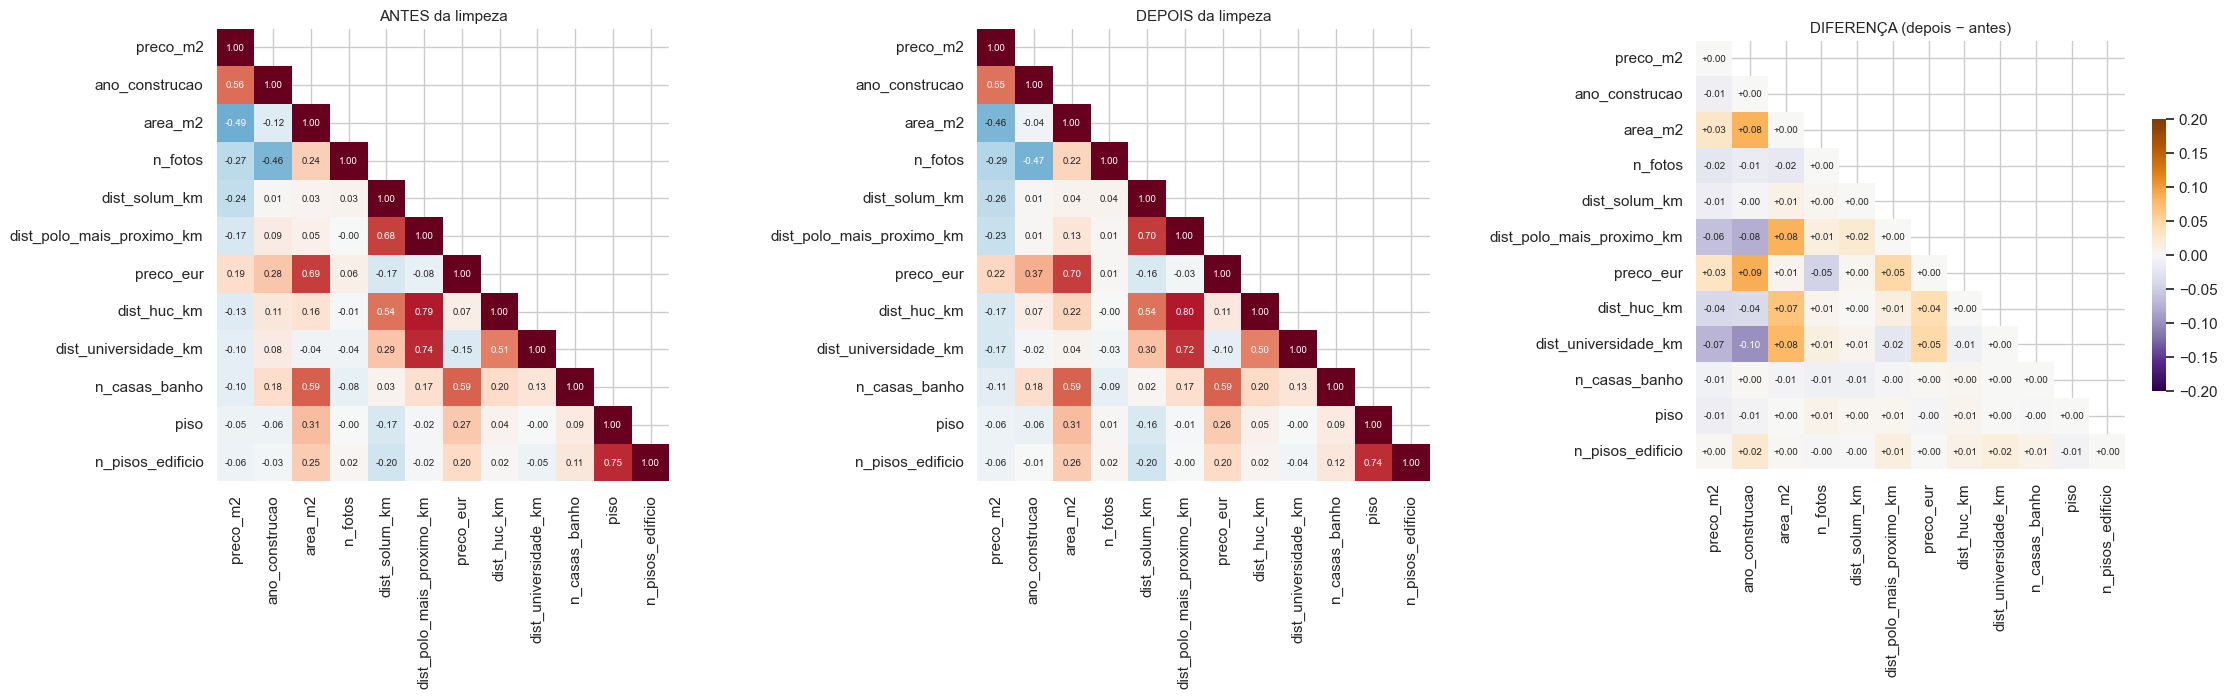

maiores mudanças na relação com o alvo:


,variação
dist_universidade_km,-0.071
dist_polo_mais_proximo_km,-0.062
dist_huc_km,-0.041
preco_eur,0.031
area_m2,0.028
n_fotos,-0.023
dist_solum_km,-0.013
piso,-0.013
ano_construcao,-0.012
n_casas_banho,-0.009


In [35]:
# Colunas que não são medidas ou que já saíram — não fazem sentido na matriz.
EXCLUIR_CORR = ["ad_id", "agencia_id", "lat", "lon", "preco_m2_site",
                "grupo_empreendimento", "raio_precisao_m"]


def heatmaps_antes_depois(antes, depois, target="preco_m2",
                          metodo="spearman", excluir=EXCLUIR_CORR):
    """
    Matriz de correlação antes e depois da limpeza, mais a diferença.

    As três partilham a mesma ordem de variáveis (pela força da relação com o
    alvo depois da limpeza), senão não se conseguem comparar. O painel da
    diferença usa uma escala apertada (±0,2) porque as mudanças são pequenas
    em valor absoluto mas grandes em proporção.
    """
    cols = [c for c in depois.select_dtypes("number").columns
            if c in antes.columns and c not in excluir]
    ca = antes[cols].corr(method=metodo)
    cd = depois[cols].corr(method=metodo)

    ordem = cd[target].abs().sort_values(ascending=False).index
    ca, cd = ca.loc[ordem, ordem], cd.loc[ordem, ordem]
    mask = np.triu(np.ones_like(cd, dtype=bool), k=1)

    fig, axes = plt.subplots(1, 3, figsize=(23, 7))
    for ax, m, titulo in [(axes[0], ca, "ANTES da limpeza"),
                          (axes[1], cd, "DEPOIS da limpeza")]:
        sns.heatmap(m, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                    annot=True, fmt=".2f", annot_kws={"size": 7},
                    square=True, cbar=False, ax=ax)
        ax.set_title(titulo, fontsize=11)

    diferenca = cd - ca
    sns.heatmap(diferenca, mask=mask, cmap="PuOr_r", center=0, vmin=-.2, vmax=.2,
                annot=True, fmt="+.2f", annot_kws={"size": 7},
                square=True, cbar_kws={"shrink": .6}, ax=axes[2])
    axes[2].set_title("DIFERENÇA (depois − antes)", fontsize=11)

    plt.tight_layout(); plt.show()
    return diferenca


diferenca = heatmaps_antes_depois(df, limpo)

print("maiores mudanças na relação com o alvo:")
display(diferenca["preco_m2"].drop("preco_m2")
        .sort_values(key=abs, ascending=False).round(3).to_frame("variação"))

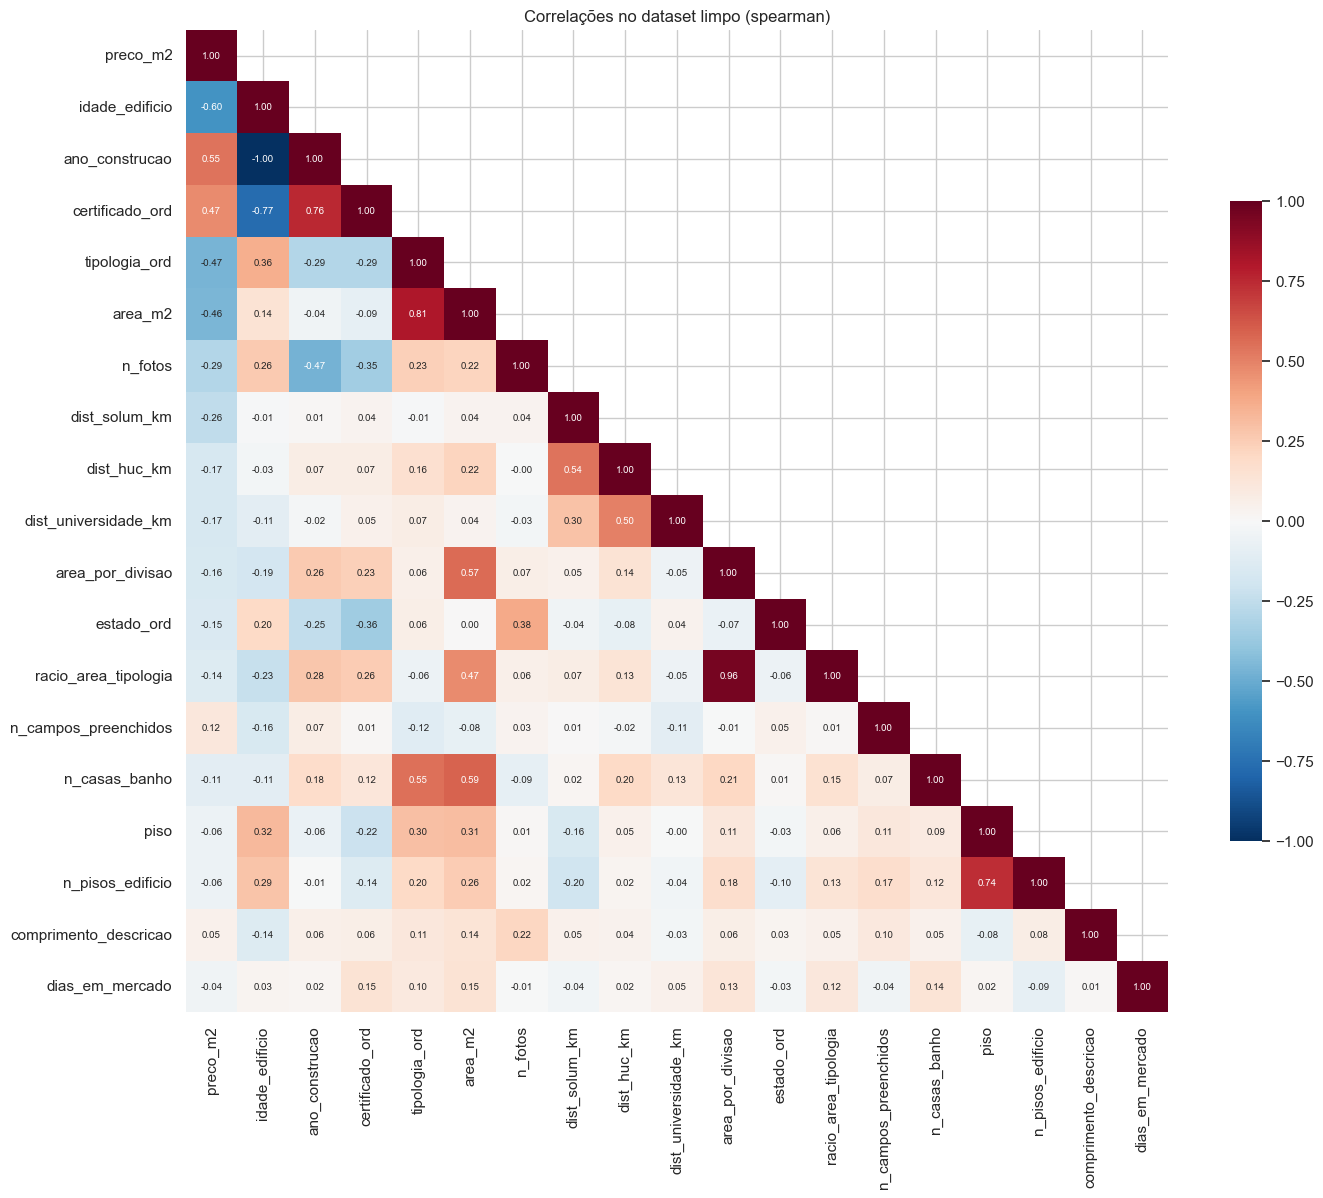

,corr com preco_m2
idade_edificio,-0.599
ano_construcao,0.546
certificado_ord,0.472
tipologia_ord,-0.466
area_m2,-0.460
n_fotos,-0.292
dist_solum_km,-0.257
dist_huc_km,-0.171
dist_universidade_km,-0.166
area_por_divisao,-0.159


In [36]:
def heatmap_final(d, target="preco_m2", cols=None, metodo="spearman"):
    """
    Correlações no dataset limpo, incluindo as features derivadas.

    Complementa o comparativo antes/depois, que por construção só mostra
    colunas que existiam nas duas versões — e portanto deixa de fora tudo o
    que a `derivar()` cria.
    """
    cols = cols or [c for c in d.select_dtypes("number").columns
                    if c not in ["ad_id", "lat", "lon", "preco_eur",
                                 "grupo_empreendimento", "raio_precisao_m",
                                 "dist_polo_mais_proximo_km"]]
    corr = d[cols].corr(method=metodo)
    ordem = corr[target].abs().sort_values(ascending=False).index
    corr = corr.loc[ordem, ordem]

    fig, ax = plt.subplots(figsize=(.6*len(cols)+3, .55*len(cols)+2))
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
                cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True,
                fmt=".2f", annot_kws={"size": 7}, square=True,
                cbar_kws={"shrink": .6}, ax=ax)
    ax.set_title(f"Correlações no dataset limpo ({metodo})")
    plt.tight_layout(); plt.show()
    return corr[target].drop(target).sort_values(key=abs, ascending=False)


forca = heatmap_final(limpo)
display(forca.round(3).to_frame("corr com preco_m2"))

#Adicionei padrao 

---
## Resumo das decisões

*Preencher no fim. Uma linha por regra: o que remove, quantas linhas, e a
justificação em meia frase. É este resumo que vai para o
`src/features/limpeza.py` e para o README.*

| regra | linhas removidas | justificação |
|---|---:|---|
| | | |